# Fitting VAE and cVAE to distribution functions

In this notebook, VAE and cVAE learn **analytically known distributions** from samples. 
Because the exact density is known, the quality of the fit can be verified directly (histogram versus exact density, Kolmogorov-Smirnov test).

| Section | Model | Target Distribution |
|---|---|---|
| 3 | VAE | 2D-Gaussian-Mixture `p(x)` |
| 4 | VAE | 3D-Gaussian-Velocity-Distribution `p(v)` (Magnitude: Maxwell-Distribution) |
| 5 | cVAE | Maxwell-Distribution with temperature as condition `p(v \| T)` |
| 6 | VAE | Influence of `kl_weight` on the accuracy |
| 7 | cVAE | Storage and Loading |

Units: `m = k_B = 1`, so `σ² = T` and `v ~ N(0, T·I)`.

> **Disclaimer:** The models in this notebook are illustrative examples, not optimized results. Architectures, hyperparameters and training settings were chosen to keep the runtime short, not to reach maximum accuracy. The reported accuracies are therefore not the best achievable with this approach; there is most likely considerable room for improvement, e.g. through tuning of `kl_weight`, the latent dimension, network size, learning rate (schedule), batch size and number of epochs.

> **Requirements:** `pip install -e ".[notebooks]"` plus `scipy` (for the exact densities and the KS test).

## 1. Setup

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scipy import stats

from neuraldist.generative_model.registry import build_model
import neuraldist.generative_model.vae  # Import registers “vae” and “cvae”
from neuraldist.training import fit_model

tf.keras.utils.set_random_seed(0)
rng = np.random.default_rng(0)

I0000 00:00:1793973995.954768  120760 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793973996.006109  120760 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793973997.908293  120760 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 2. Helperfunctions

In [2]:
def make_dataset(*arrays, batch_size=256):
    """(x,) for unconditional, (x, c) for conditional."""
    ds = tf.data.Dataset.from_tensor_slices(arrays)
    return ds.shuffle(len(arrays[0])).batch(batch_size).prefetch(tf.data.AUTOTUNE)


def plot_history(history, title):
    fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
    for ax, k in zip(axes, ["loss", "recon", "kl"]):
        ax.plot(history.history[k])
        ax.set(title=f"{title}: {k}", xlabel="Epoch")
    fig.tight_layout()
    plt.show()


def ks_statistic(samples, cdf):
    """Kolmogorov-Smirnov-Distance between samples and samples and exact CDF (0 = perfect)."""
    return stats.kstest(samples, cdf).statistic

## 3. VAE: 2D-Gaussian-Mixture

Three components with different weights and covariances. The exact density is the weighted sum of the individual densities.


In [3]:
weights = np.array([0.3, 0.4, 0.3])
means = np.array([[-2.0, -1.0], [2.0, -1.0], [0.0, 2.0]])
covs = np.array([[[0.30, 0.15], [0.15, 0.25]],
                 [[0.40, -0.10], [-0.10, 0.20]],
                 [[0.15, 0.00], [0.00, 0.35]]])


def sample_mixture(n):
    comp = rng.choice(len(weights), size=n, p=weights)
    x = np.stack([rng.multivariate_normal(means[k], covs[k]) for k in comp])
    return x.astype("float32")


def mixture_pdf(grid):
    return sum(w * stats.multivariate_normal(m, c).pdf(grid) for w, m, c in zip(weights, means, covs))


def mixture_marginal_cdf(x1):
    """CDF of the x₁ marginal distribution (mixture of 1D normal distributions)."""
    return sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).cdf(x1) for w, m, c in zip(weights, means, covs))


x_gm = sample_mixture(30_000)
print("Training data:", x_gm.shape)

Training data: (30000, 2)


E0000 00:00:1793974001.105012  120760 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


{'kl': 3.0027, 'loss': 0.3957, 'recon': 0.0954}


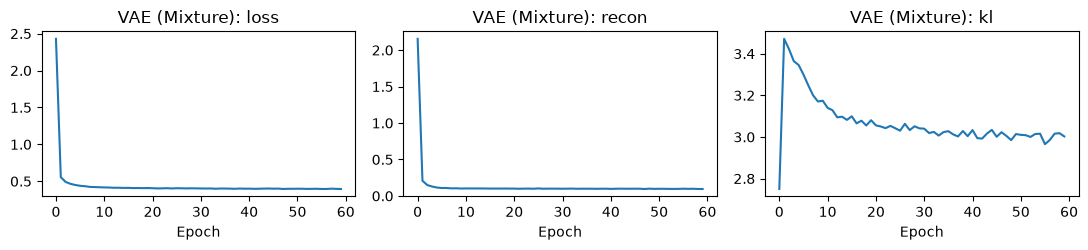

In [4]:
vae_gm = build_model("vae", x_dim=2, latent_dim=2, kl_weight=0.1)
history = fit_model(vae_gm, x_gm, epochs=60)
print({k: round(v[-1], 4) for k, v in history.history.items()})
plot_history(history, "VAE (Mixture)")

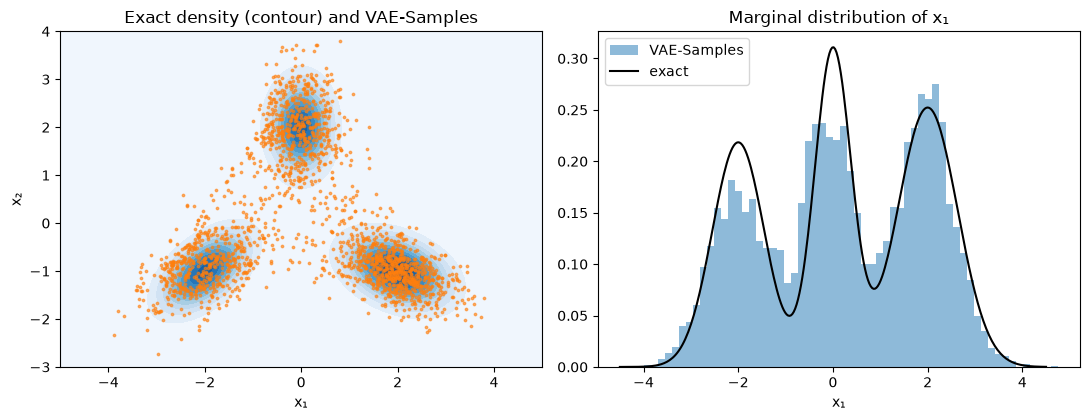

KS distance of the x₁ marginal distribution: 0.029
Component weights ~ Percentage of samples near the mean values:
  Component 0: Samples 0.21 | Training data 0.25
  Component 1: Samples 0.33 | Training data 0.33
  Component 2: Samples 0.22 | Training data 0.26


In [13]:
samples_gm = vae_gm.sample(10_000).numpy()          # unconditional: (n_samples, x_dim)

# exact density on grid
gx, gy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3, 4, 200))
density = mixture_pdf(np.dstack([gx, gy]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].contourf(gx, gy, density, levels=15, cmap="Blues")
axes[0].scatter(samples_gm[:2000, 0], samples_gm[:2000, 1], s=3, color="tab:orange", alpha=0.6)
axes[0].set(title="Exact density (contour) and VAE-Samples", xlabel="x₁", ylabel="x₂")

grid1 = np.linspace(-4.5, 4.5, 300)
marg = sum(w * stats.norm(m[0], np.sqrt(c[0, 0])).pdf(grid1) for w, m, c in zip(weights, means, covs))
axes[1].hist(samples_gm[:, 0], bins=60, density=True, alpha=0.5, label="VAE-Samples")
axes[1].plot(grid1, marg, "k", label="exact")
axes[1].set(title="Marginal distribution of x₁", xlabel="x₁")
axes[1].legend()
fig.tight_layout()
plt.show()

print(f"KS distance of the x₁ marginal distribution: {ks_statistic(samples_gm[:, 0], mixture_marginal_cdf):.3f}")
print("Component weights ~ Percentage of samples near the mean values:")
for k, m in enumerate(means):
    frac = (np.linalg.norm(samples_gm - m, axis=1) < 1.0).mean()
    frac_true = (np.linalg.norm(x_gm - m, axis=1) < 1.0).mean()
    print(f"  Component {k}: Samples {frac:.2f} | Training data {frac_true:.2f}")

**Observation:** 
The three components are identified at the correct locations and with appropriate weights. However, the VAE smooths the results: the maxima are slightly lower and the edges are wider, and there are individual samples between the components. This is due to the continuous latent space and can be influenced by `kl_weight` and the training duration (see Section 6). Since architecture and training settings were not tuned, the smoothing can most likely be reduced further.

## 4. VAE: 3D-Gaussian-Velocity-Distribution

The velocity components are independently normally distributed, `v ~ N(0, σ²·I)`, where `σ = 1`.
The **magnitude** `|v|` is then Maxwell-distributed, `f(v) = √(2/π) · v²/σ³ · exp(-v²/2σ²)`.
The VAE learns `v` (3D); the derived magnitude distribution is evaluated.

{'kl': 5.7235, 'loss': 0.7294, 'recon': 0.1571}


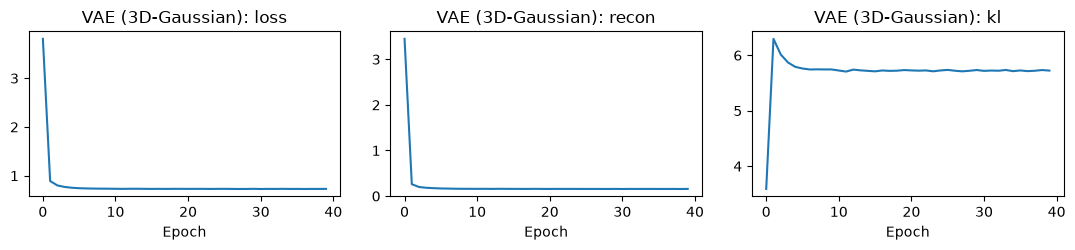

In [6]:
sigma = 1.5
v = rng.normal(0.0, sigma, size=(30_000, 3)).astype("float32")

vae_mw = build_model("vae", x_dim=3, latent_dim=3, kl_weight=0.1)
history = fit_model(vae_mw, v, epochs=40)
print({k: round(val[-1], 4) for k, val in history.history.items()})
plot_history(history, "VAE (3D-Gaussian)")

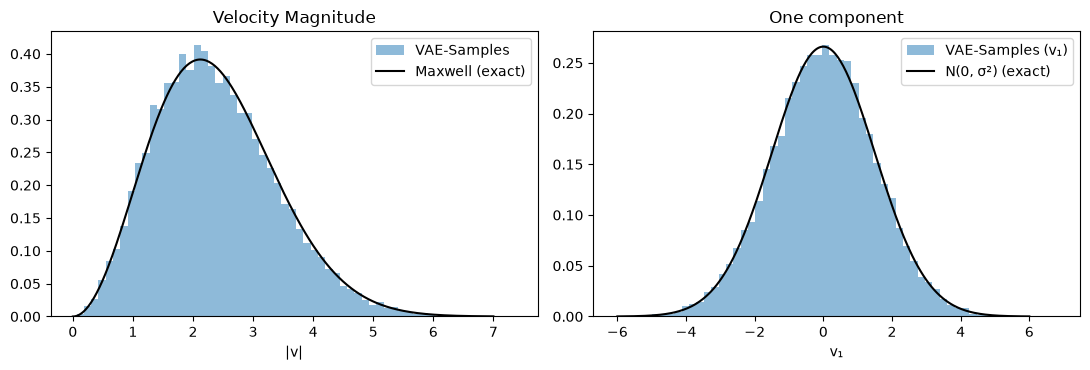

Standard deviation per component (target 1.5): [1.506 1.464 1.486]
Mean speed: Samples 2.369 | exact 2.394
KS distance of the magnitude:   0.014


In [7]:
samples_v = vae_mw.sample(20_000).numpy()
speed = np.linalg.norm(samples_v, axis=1)

maxwell = stats.maxwell(scale=sigma)
vs = np.linspace(0, 7, 300)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(speed, bins=60, density=True, alpha=0.5, label="VAE-Samples")
axes[0].plot(vs, maxwell.pdf(vs), "k", label="Maxwell (exact)")
axes[0].set(title="Velocity Magnitude", xlabel="|v|")
axes[0].legend()

grid = np.linspace(-6, 6, 300)
axes[1].hist(samples_v[:, 0], bins=60, density=True, alpha=0.5, label="VAE-Samples (v₁)")
axes[1].plot(grid, stats.norm(0, sigma).pdf(grid), "k", label="N(0, σ²) (exact)")
axes[1].set(title="One component", xlabel="v₁")
axes[1].legend()
fig.tight_layout()
plt.show()

print(f"Standard deviation per component (target {sigma}):", samples_v.std(0).round(3))
print(f"Mean speed: Samples {speed.mean():.3f} | exact {maxwell.mean():.3f}")
print(f"KS distance of the magnitude:   {ks_statistic(speed, maxwell.cdf):.3f}")

## 5. cVAE: Temperature dependent Maxwell Distribution

Now the temperature is the condition `c = T ∈ [0.5, 2]`, and `v | T ~ N(0, T·I)` holds.
The model is supposed to learn a **single** distribution that scales correctly with `T`.

The dataset provides `(v, T)` pairs; `build_model(“cvae”, ..., cond_dim=1)` builds the conditional model.

{'kl': 4.7352, 'loss': 0.628, 'recon': 0.1545}


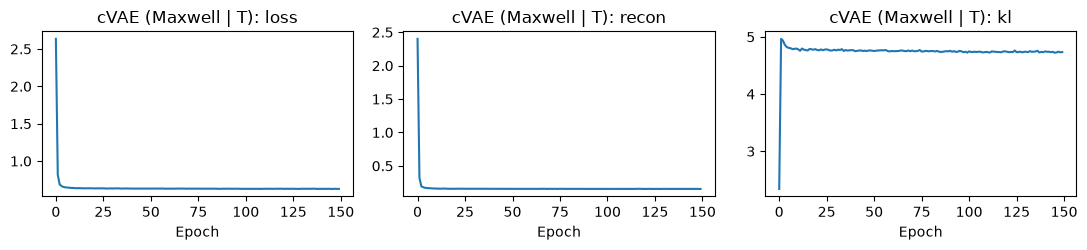

In [8]:
n = 30_000
T_train = rng.uniform(0.5, 2.0, size=(n, 1)).astype("float32")
v_train = (rng.standard_normal((n, 3)) * np.sqrt(T_train)).astype("float32")

cvae = build_model("cvae", x_dim=3, cond_dim=1, latent_dim=3, kl_weight=0.1)
history = fit_model(cvae, v_train, T_train, epochs=150)
print({k: round(val[-1], 4) for k, val in history.history.items()})
plot_history(history, "cVAE (Maxwell | T)")

### Conditional Sampling for multiple temperatures

`sample(n_samples, cond)` where `cond` is of the form `(B, 1)` returns `(B, n_samples, 3)`: `n_samples` samples **per temperature**.

cond: (3, 1) -> samples: (3, 20000, 3)


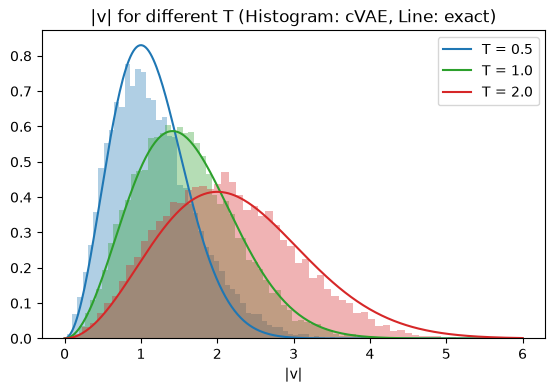

 T  | σ_samples/σ_exact | KS-Distance
0.5 |              1.06 | 0.048
1.0 |              0.99 | 0.018
2.0 |              0.93 | 0.055


In [9]:
temps = np.array([[0.5], [1.0], [2.0]], dtype="float32")
samples_T = cvae.sample(20_000, cond=temps).numpy()
print("cond:", temps.shape, "-> samples:", samples_T.shape)

fig, ax = plt.subplots(figsize=(6.5, 4))
vs = np.linspace(0, 6, 300)
rows = []
for T, s, color in zip(temps[:, 0], samples_T, ["tab:blue", "tab:green", "tab:red"]):
    sp = np.linalg.norm(s, axis=1)
    exact = stats.maxwell(scale=np.sqrt(T))
    ax.hist(sp, bins=60, density=True, alpha=0.35, color=color)
    ax.plot(vs, exact.pdf(vs), color=color, label=f"T = {T:.1f}")
    rows.append((T, s.std(0).mean() / np.sqrt(T), ks_statistic(sp, exact.cdf)))
ax.set(title="|v| for different T (Histogram: cVAE, Line: exact)", xlabel="|v|")
ax.legend()
plt.show()

print(" T  | σ_samples/σ_exact | KS-Distance")
for T, ratio, ks in rows:
    print(f"{T:.1f} | {ratio:17.2f} | {ks:.3f}")

**Observation:** The distribution expands correctly with `T`; a single model covers all temperatures. At the edges of the training range, the width is slightly distorted (slightly too narrow at `T=2`, slightly too wide at `T=0.5`). This is the typical trade-off between regularization (KL) and reconstruction. By tuning `kl_weight`, architecture and training length these edge distortions can most likely be reduced further.

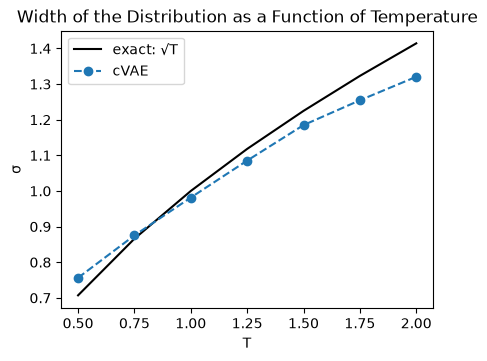

In [10]:
# Also for temperatures outside the training range: Scaling the standard deviation
T_grid = np.linspace(0.5, 2.0, 7, dtype="float32")[:, None]
s_grid = cvae.sample(5000, cond=T_grid).numpy()          # (7, 5000, 3)
sigma_model = s_grid.std(axis=1).mean(axis=1)

fig, ax = plt.subplots(figsize=(4.8, 3.6))
ax.plot(T_grid[:, 0], np.sqrt(T_grid[:, 0]), "k", label="exact: √T")
ax.plot(T_grid[:, 0], sigma_model, "o--", label="cVAE")
ax.set(title="Width of the Distribution as a Function of Temperature", xlabel="T", ylabel="σ")
ax.legend()
plt.show()

## 6. Influence of `kl_weight` on the accuracy

The VAE decoder outputs the mean; no noise is added. A large KL weight forces the latent space
toward a standard normal distribution and causes the samples to **shrink** (standard deviation too small).
Small values result in a sharper reconstruction, but the latent space becomes less regular.

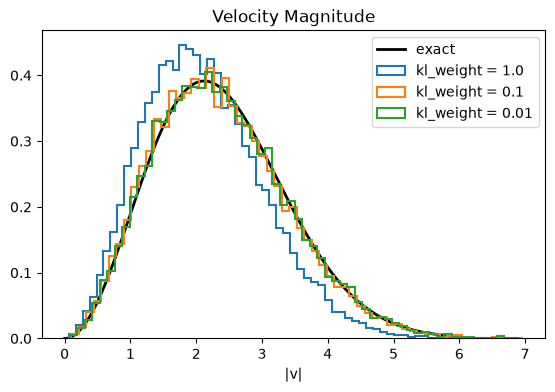

kl_weight | σ_samples (target 1.0) | KS-Distance
      1.0 |                   1.32 | 0.118
      0.1 |                   1.48 | 0.018
     0.01 |                   1.49 | 0.010


In [11]:
results = {}
for kl in [1.0, 0.1, 0.01]:
    tf.keras.utils.set_random_seed(0)
    m = build_model("vae", x_dim=3, latent_dim=3, kl_weight=kl)
    fit_model(m, v, epochs=40)
    s = m.sample(20_000).numpy()
    results[kl] = np.linalg.norm(s, axis=1), s.std(0).mean()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(vs, maxwell.pdf(vs), "k", lw=2, label="exact")
for kl, (sp, _) in results.items():
    ax.hist(sp, bins=60, density=True, histtype="step", lw=1.5, label=f"kl_weight = {kl}")
ax.set(title="Velocity Magnitude", xlabel="|v|")
ax.legend()
plt.show()

print("kl_weight | σ_samples (target 1.0) | KS-Distance")
for kl, (sp, sd) in results.items():
    print(f"{kl:9} | {sd:22.2f} | {ks_statistic(sp, maxwell.cdf):.3f}")

## 7. Storage and Loading

To load the model, a model with **the same architecture** is built and initialized with `warmup()`
(`warmup()` sets all weights without training anything).

In [12]:
path = Path(tempfile.mkdtemp()) / "cvae_maxwell.weights.h5"

cvae.warmup()
cvae.save_weights(str(path))

restored = build_model("cvae", x_dim=3, cond_dim=1, latent_dim=3, kl_weight=0.1)
restored.warmup()
restored.load_weights(str(path))

same = all(np.allclose(a, b) for a, b in zip(cvae.get_weights(), restored.get_weights()))
print("Weights identical:", same)

Weights identical: True
